# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [1]:
# ── Заповніть три поля ──────────────────────────────────────────
SURNAME_NAME = 'Левченко Денис'      # прізвище та ім'я
GROUP        = 'ШІ-33'      # шифр групи, наприклад СШІ-31
NUMBER       = 4       # ваш номер за списком групи (1–30)

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Левченко Денис | ШІ-33 | номер 4


In [2]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 4   ·   Левченко Денис   ·   ШІ-33

   Ринок:  Kherson
   Товар:  сметана   (у наборі даних: Sour cream - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** | |
| **Підпис** | |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [3]:
# Завдання 1. Підготовка ряду
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

prices = pd.read_csv('ціни_україна_2014_2017.csv')
prices['date'] = pd.to_datetime(dict(year=prices['рік'], month=prices['місяць'], day=1))
raw = (prices[(prices['ринок'] == MARKET) & (prices['товар'] == GOOD)]
       .set_index('date')['ціна'].sort_index())
unit = prices.loc[(prices['ринок'] == MARKET) & (prices['товар'] == GOOD), ['одиниця', 'валюта']].iloc[0]
print('ряд:', MARKET, '|', GOOD, '| одиниця:', unit['одиниця'], '| валюта:', unit['валюта'])

grid = pd.date_range('2014-03-01', '2017-12-01', freq='MS')
s = raw.reindex(grid)
print('місяців у сітці     :', len(grid))
print('мають вимір          :', int(s.notna().sum()))
print('пропущені місяці     :', [d.strftime('%m.%Y') for d in s[s.isna()].index])

per_month = prices.groupby('date').size().reindex(grid, fill_value=0)
print('записів у всьому наборі за 08.2017:', int(per_month['2017-08-01']))
print('місяці без жодного запису в наборі:', [d.strftime('%m.%Y') for d in per_month[per_month == 0].index])

ряд: Kherson | Sour cream - Retail | одиниця: L | валюта: UAH
місяців у сітці     : 46
мають вимір          : 45
пропущені місяці     : ['08.2017']
записів у всьому наборі за 08.2017: 0
місяці без жодного запису в наборі: ['08.2017']


**Висновок до завдання 1:**

1. Повна місячна сітка 03.2014–12.2017 має **46 місяців**, вимір є для **45**.
2. Пропущено один місяць — **серпень 2017 (08.2017)**.
3. Пропуск не пов'язаний із ринком Херсона: у всьому наборі за 08.2017 немає **жодного** запису (0 рядків для всіх ринків і товарів) — джерело (WFP) не опублікувало цей місяць. Тому пропуск у ряді **один**, і такий самий він в усіх рядах набору. Решта 45 місяців мають по одному виміру; одиниця — літр, ціни в гривнях.

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

In [4]:
# Завдання 2. Заповнення пропуску
variants = pd.DataFrame({
    'перенесення останнього': s.ffill(),
    'лінійна інтерполяція': s.interpolate('linear'),
    'середнє 4 сусідів': s.fillna(s.rolling(5, center=True, min_periods=1).mean()),
})
print('значення за 08.2017:')
print(variants.loc['2017-08-01'].round(4).to_string())
print()
print('сусіди: 07.2017 = %.4f, 09.2017 = %.4f' % (s['2017-07-01'], s['2017-09-01']))

y = s.interpolate('linear')
print('обрано лінійну інтерполяцію: 08.2017 =', round(y['2017-08-01'], 4))

coverage = prices.groupby('ринок')['date'].agg(['min', 'max', 'nunique'])
print()
print('ринки з неповним рядом:')
print(coverage[coverage['nunique'] < 45].to_string())

значення за 08.2017:
перенесення останнього    44.5400
лінійна інтерполяція      44.3734
середнє 4 сусідів         44.5900

сусіди: 07.2017 = 44.5400, 09.2017 = 44.2067
обрано лінійну інтерполяцію: 08.2017 = 44.3734

ринки з неповним рядом:
                     min        max  nunique
ринок                                       
Crimea        2014-03-01 2014-03-01        1
Donetska      2014-03-01 2017-12-01       42
Luhanska      2014-03-01 2017-12-01       40
m. Sevastopol 2014-03-01 2014-04-01        2


**Висновок до завдання 2:**

1. Значення за 08.2017: перенесення останнього — **44,54** грн; лінійна інтерполяція — **44,37** грн; середнє чотирьох сусідів (06, 07, 09 і 10.2017) — **44,59** грн. Сусіди: 07.2017 = 44,54, 09.2017 = 44,21.
2. Обрано **лінійну інтерполяцію (44,37 грн)**. Пропуск один і стоїть між двома відомими місяцями, а ціна в цей час майже не змінювалась (−0,33 грн за два місяці), тож середина між найближчими сусідами — найменш довільне припущення. Перенесення останнього штучно робить у серпні нульову зміну й переносить усю зміну на вересень. Середнє чотирьох сусідів захоплює вже жовтневий стрибок (45,68 грн) і дає 44,59 — вище за обох найближчих сусідів. Крім того, Orange має той самий тип (Interpolate → Linear interpolation), тож обидва середовища отримають однаковий ряд.
3. Заповнювати **неприпустимо**, коли відсутність даних означає, що спостереження припинилось, а не випадково пропущене. У цьому наборі Крим має лише 03.2014, Севастополь — 03–04.2014 (після анексії ціни не збиралися), у Донецькій області немає 08, 09 і 12.2014, а в Луганській — 08–12.2014 (бойові дії). «Заповнити» Крим на 2014–2017 означало б вигадати 44 місяці цін на ринку, де їх ніхто не вимірював: інтерполяція там стає фабрикацією даних, а не оцінкою одного пропущеного виміру.

## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

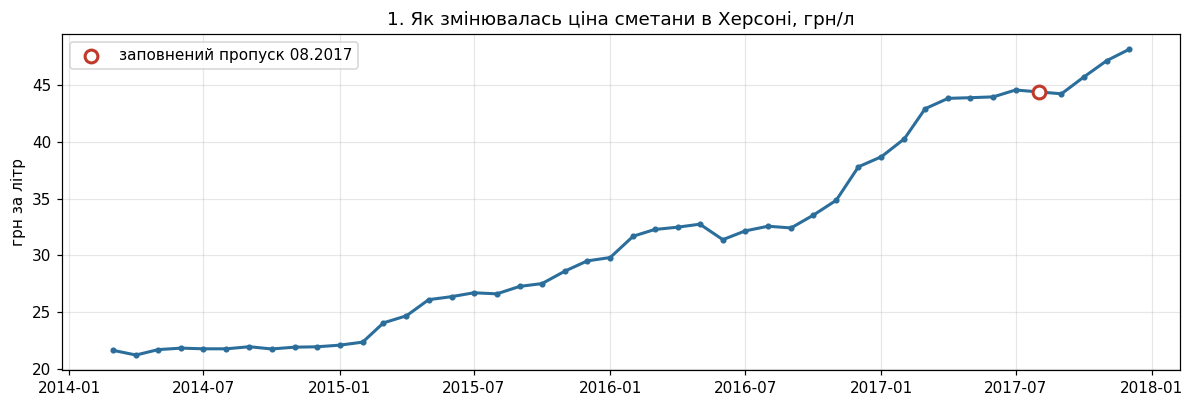

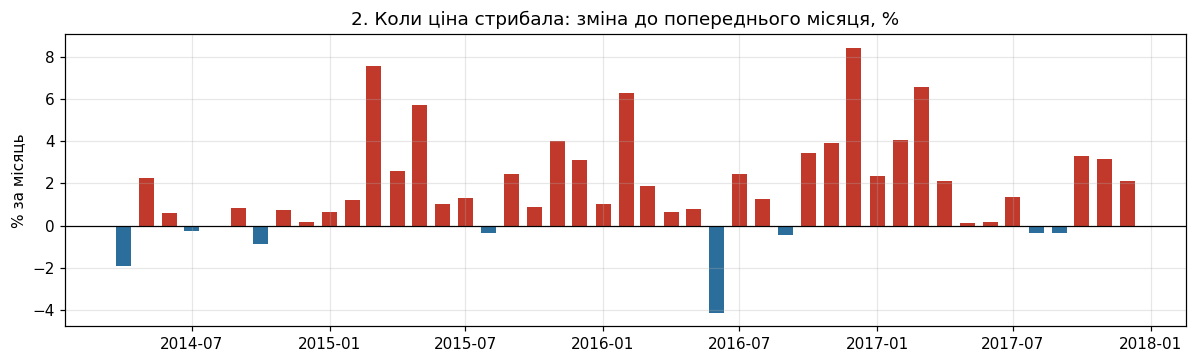

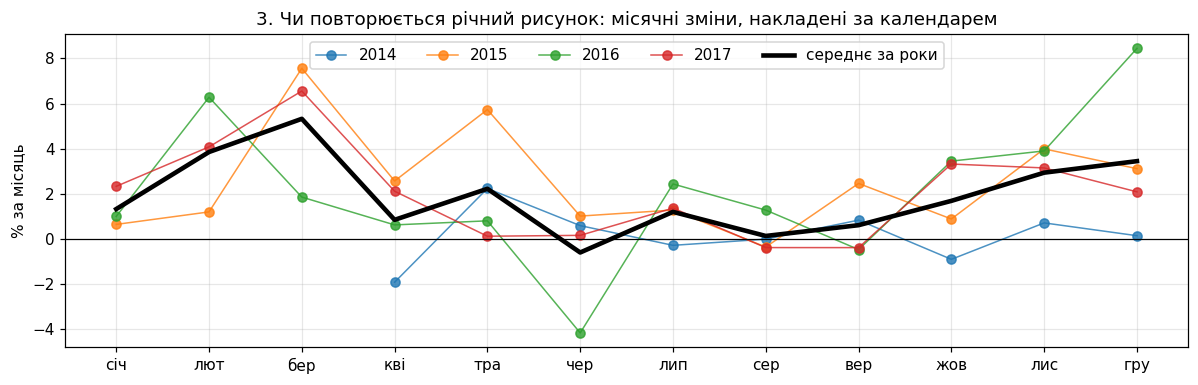

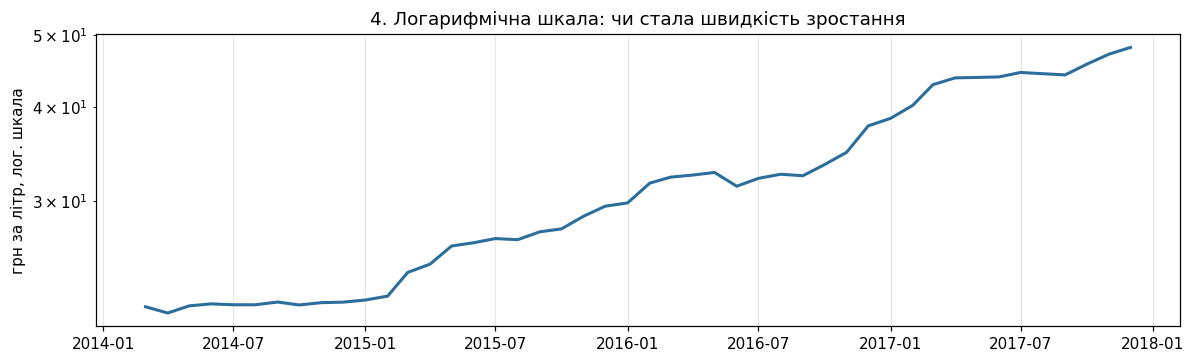

найбільші місячні зростання, %: {'12.2016': 8.45, '03.2015': 7.56, '03.2017': 6.56, '02.2016': 6.28, '05.2015': 5.74}
місяців зі зниженням ціни: 8 | найбільше зниження: 06.2016 -4.15 %
зростання за рік, разів: {2014: 1.014, 2015: 1.335, 2016: 1.267, 2017: 1.244}
середня зміна в грудні–березні: 3.49 % | у травні–вересні: 0.72 %


In [5]:
# Завдання 3. Візуальна розвідка
filled = y.index == pd.Timestamp('2017-08-01')

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(y.index, y.values, color='#2C6E9B', lw=2, marker='o', ms=3)
ax.scatter(y.index[filled], y[filled], s=70, facecolor='white', edgecolor='#C0392B', lw=2, zorder=5,
           label='заповнений пропуск 08.2017')
ax.set_title('1. Як змінювалась ціна сметани в Херсоні, грн/л')
ax.set_ylabel('грн за літр')
ax.legend()
plt.tight_layout()
plt.show()

mom = y.pct_change() * 100
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.bar(mom.index, mom.values, width=20, color=np.where(mom > 0, '#C0392B', '#2C6E9B'))
ax.axhline(0, color='black', lw=0.8)
ax.set_title('2. Коли ціна стрибала: зміна до попереднього місяця, %')
ax.set_ylabel('% за місяць')
plt.tight_layout()
plt.show()

seas = pd.DataFrame({'рік': mom.index.year, 'місяць': mom.index.month, 'зміна': mom.values}).dropna()
fig, ax = plt.subplots(figsize=(11, 3.6))
for year, g in seas.groupby('рік'):
    ax.plot(g['місяць'], g['зміна'], marker='o', lw=1, alpha=0.8, label=str(year))
ax.plot(range(1, 13), seas.groupby('місяць')['зміна'].mean().reindex(range(1, 13)), color='black', lw=3,
        label='середнє за роки')
ax.axhline(0, color='black', lw=0.8)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(['січ', 'лют', 'бер', 'кві', 'тра', 'чер', 'лип', 'сер', 'вер', 'жов', 'лис', 'гру'])
ax.set_title('3. Чи повторюється річний рисунок: місячні зміни, накладені за календарем')
ax.set_ylabel('% за місяць')
ax.legend(ncol=5)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.semilogy(y.index, y.values, color='#2C6E9B', lw=2)
ax.set_title('4. Логарифмічна шкала: чи стала швидкість зростання')
ax.set_ylabel('грн за літр, лог. шкала')
plt.tight_layout()
plt.show()

print('найбільші місячні зростання, %:', {d.strftime('%m.%Y'): round(v, 2) for d, v in mom.nlargest(5).items()})
print('місяців зі зниженням ціни:', int((mom < 0).sum()), '| найбільше зниження:', mom.idxmin().strftime('%m.%Y'),
      round(mom.min(), 2), '%')
year_growth = y.groupby(y.index.year).agg(['first', 'last'])
print('зростання за рік, разів:', (year_growth['last'] / year_growth['first']).round(3).to_dict())
winter = mom[mom.index.month.isin([12, 1, 2, 3])].mean()
summer = mom[mom.index.month.isin([5, 6, 7, 8, 9])].mean()
print('середня зміна в грудні–березні: %.2f %% | у травні–вересні: %.2f %%' % (winter, summer))

**Висновок до завдання 3:**

1. Кожен графік ставить своє питання:
   * **Графік 1 (лінія рівня)** — як змінювалась ціна, чи є тренд і злами. Лінія, бо точки впорядковані в часі й сусідні місяці пов'язані. Вісь Y не від нуля: питання про зміну, а не про частку від нуля, і лінія кодує величину положенням, а не довжиною. Заповнений місяць позначено окремим маркером, щоб не видавати оцінку за вимір.
   * **Графік 2 (стовпчики місячної зміни, %)** — коли були стрибки і наскільки великі. Тут довжина стовпчика кодує величину, тому відлік від нуля обов'язковий; колір показує знак. Відсотки, а не гривні, бо зміна на 1 грн у 2014 і у 2017 — різна за відносним розміром.
   * **Графік 3 (сезонний графік змін)** — чи повторюється рисунок усередині року. Вісь X — календарний місяць, тож роки накладаються; беруться зміни, а не рівень, бо рівень із трендом розвів би роки по вертикалі.
   * **Графік 4 (логарифмічна шкала)** — чи стала швидкість зростання. На лог-шкалі однаковий відсоток дає однаковий нахил: ціна майже стоїть у 2014-му, різко прискорюється з весни 2015-го і знову круто росте взимку 2016–2017.
2. Несподівана знахідка: найбільший місячний стрибок стався не у 2015-му, а в **грудні 2016 (+8,45 %)**. Зростання зосереджене в грудні–березні — у середньому **+3,49 %** за місяць проти **+0,72 %** у травні–вересні. Зимове подорожчання повторюється щороку. Ціна знижувалась лише 8 разів із 45, найбільше — на 4,15 % у червні 2016.

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

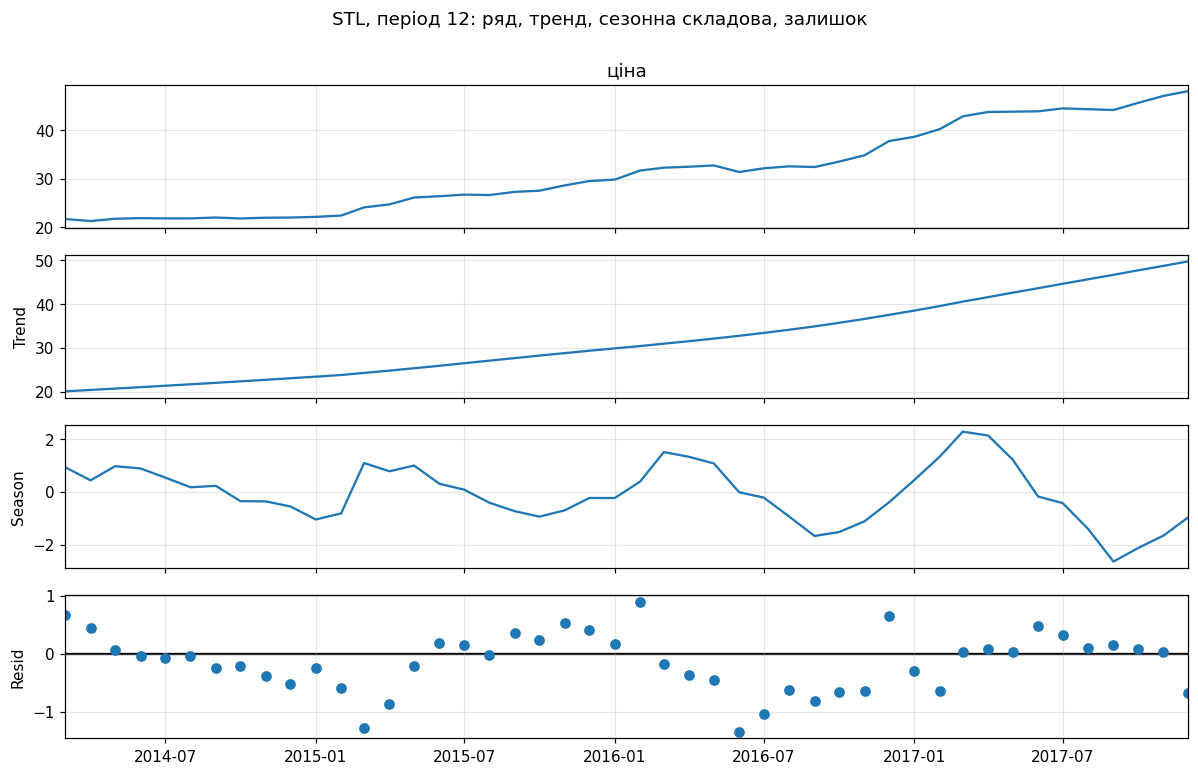

сила сезонності F_S = 0.823
сила тренду     F_T = 0.997
амплітуда сезонної складової: 4.92 грн
перевірка робастним STL: F_S = 0.525
сезонна складова за календарними місяцями, грн:
{1: -0.28, 2: 0.3, 3: 1.45, 4: 1.17, 5: 1.06, 6: 0.25, 7: -0.01, 8: -0.65, 9: -1.21, 10: -1.24, 11: -0.96, 12: -0.54}


In [6]:
# Завдання 4. Розкладання на складові
from statsmodels.tsa.seasonal import STL

stl = STL(y, period=12).fit()
fig = stl.plot()
fig.set_size_inches(11, 7)
fig.suptitle('STL, період 12: ряд, тренд, сезонна складова, залишок', y=1.0)
plt.tight_layout()
plt.show()

F_S = max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
F_T = max(0, 1 - stl.resid.var() / (stl.trend + stl.resid).var())
print('сила сезонності F_S = %.3f' % F_S)
print('сила тренду     F_T = %.3f' % F_T)
print('амплітуда сезонної складової: %.2f грн' % (stl.seasonal.max() - stl.seasonal.min()))

stl_r = STL(y, period=12, robust=True).fit()
print('перевірка робастним STL: F_S = %.3f' % max(0, 1 - stl_r.resid.var() / (stl_r.seasonal + stl_r.resid).var()))
by_month = stl.seasonal.groupby(stl.seasonal.index.month).mean()
print('сезонна складова за календарними місяцями, грн:')
print(by_month.round(2).to_dict())

**Висновок до завдання 4:**

1. Чотирипанельний графік — вище: ряд, тренд, сезонна складова, залишок.
2. **F_S = 0,823**, **F_T = 0,997** (STL, період 12). Перевірка робастним STL дає F_S = 0,525.
3. **Сезонність у ряді є**: F_S = 0,82 значно вища за поріг 0,3, і робастна оцінка 0,53 теж вища. Сезонна складова щороку має той самий рисунок: найвища в березні–травні (+1,1…+1,5 грн), найнижча у вересні–жовтні (−1,2 грн). Ціна підтягується взимку–навесні й стоїть на місці влітку–восени, що збігається з графіком 3 і з сезонністю виробництва молока (взимку його менше). Проте тренд набагато сильніший (F_T = 0,997): амплітуда сезонної складової — 4,9 грн, а зростання за період — 26 грн. До того ж на 46 точках (менше 4 повних циклів) оцінка сезонності нестійка, тож у прогнозах сезонність майже нічого не дає (див. завдання 6).

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

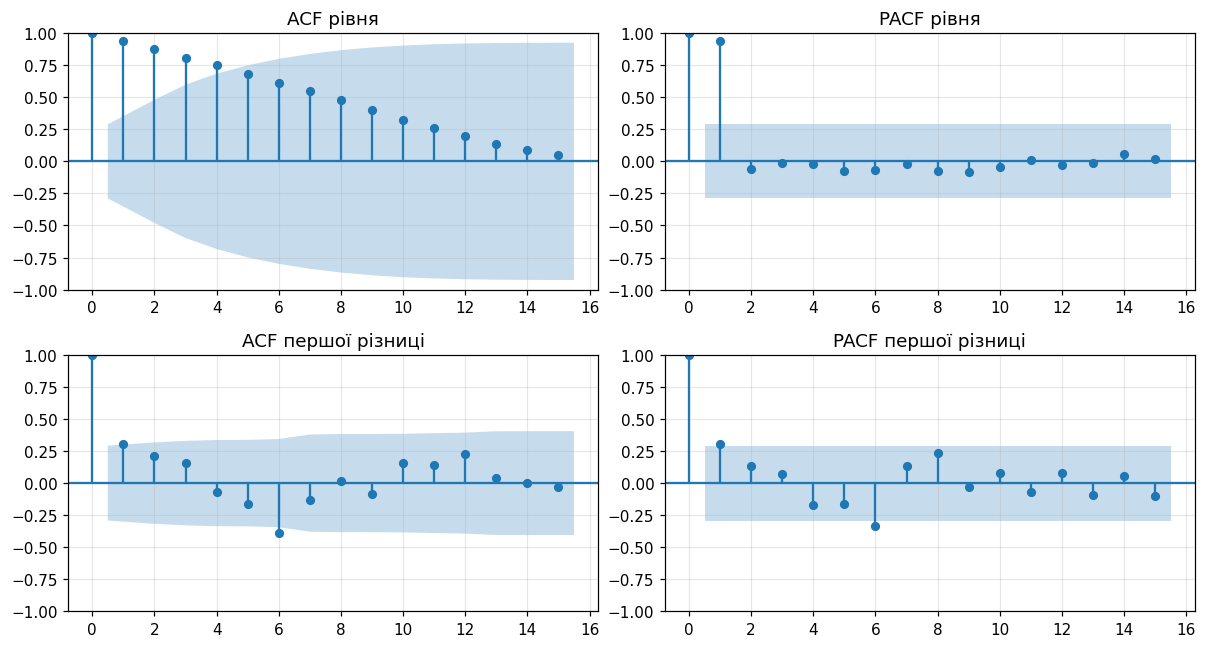

,ADF p (H0: нестаціонарний),KPSS p (H0: стаціонарний)
ряд,,
рівень,0.9991,0.01
перша різниця,0.0015,0.10


межа значущості ±0.292 (n = 45)
ACF різниці, лаги 1–12 : [ 0.3   0.21  0.16 -0.07 -0.16 -0.39 -0.13  0.02 -0.08  0.15  0.14  0.23]
PACF різниці, лаги 1–12: [ 0.3   0.13  0.07 -0.17 -0.16 -0.34  0.13  0.24 -0.03  0.08 -0.07  0.08]


In [7]:
# Завдання 5. Стаціонарність
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss

warnings.filterwarnings('ignore')
dy = y.diff().dropna()
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
plot_acf(y, lags=15, ax=axes[0, 0], title='ACF рівня')
plot_pacf(y, lags=15, ax=axes[0, 1], method='ywm', title='PACF рівня')
plot_acf(dy, lags=15, ax=axes[1, 0], title='ACF першої різниці')
plot_pacf(dy, lags=15, ax=axes[1, 1], method='ywm', title='PACF першої різниці')
plt.tight_layout()
plt.show()

rows = []
for name, x in [('рівень', y), ('перша різниця', dy)]:
    rows.append({'ряд': name,
                 'ADF p (H0: нестаціонарний)': adfuller(x, autolag='AIC')[1],
                 'KPSS p (H0: стаціонарний)': kpss(x, regression='c', nlags='auto')[1]})
tests = pd.DataFrame(rows).set_index('ряд')
display(tests.round(4))

from statsmodels.tsa.stattools import acf, pacf
print('межа значущості ±%.3f (n = %d)' % (1.96 / np.sqrt(len(dy)), len(dy)))
print('ACF різниці, лаги 1–12 :', np.round(acf(dy, nlags=12)[1:], 2))
print('PACF різниці, лаги 1–12:', np.round(pacf(dy, nlags=12, method='ywm')[1:], 2))

**Висновок до завдання 5:**

1. Графіки ACF і PACF до та після диференціювання — вище.
2. p-значення: рівень — ADF **0,9991**, KPSS **0,01**; перша різниця — ADF **0,0015**, KPSS **0,10**. KPSS у statsmodels обрізає p таблицею: для рівня справжнє p ще менше 0,01, для різниці — більше 0,10.
3. **Рівень нестаціонарний**: ADF не відхиляє H₀ «нестаціонарний» (p = 0,999), а KPSS відхиляє H₀ «стаціонарний» (p ≤ 0,01). **Перша різниця стаціонарна**: ADF відхиляє H₀ (p = 0,0015), KPSS не відхиляє (p ≥ 0,10). Обидва тести **узгоджуються** для обох рядів, тож порядок диференціювання d = 1.
4. Суперечності немає. ACF рівня згасає повільно (0,94 на лагу 1 → 0,20 на лагу 12) — типова ознака тренду. У різниці лаг 1 = 0,30 ледь виходить за межу ±0,29, а значущий від'ємний лаг 6 (−0,39) показує пів­річний рисунок: зимові стрибки змінюються літнім затишшям.

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

In [8]:
# Завдання 6. Базисні прогнози та ретроспективна перевірка
FOLDS, H = 7, 3
values = y.values
n = len(values)


def folds():
    for f in range(1, FOLDS + 1):
        yield f, values[:n - H * f], values[n - H * f:n - H * f + H]


def forecast(method, train, h):
    if method == 'наївний':
        return np.repeat(train[-1], h)
    if method == 'сезонний наївний':
        return np.array([train[len(train) - 12 + i] for i in range(h)])
    if method == 'середнє':
        return np.repeat(train.mean(), h)
    if method == 'дрейф':
        slope = (train[-1] - train[0]) / (len(train) - 1)
        return train[-1] + slope * np.arange(1, h + 1)


def scores(true, pred):
    e = true - pred
    return {'MAE': np.mean(np.abs(e)), 'RMSE': np.sqrt(np.mean(e ** 2)), 'MAPE, %': np.mean(np.abs(e / true)) * 100}


BASELINES = ['наївний', 'сезонний наївний', 'середнє', 'дрейф']
cv = {}
for m in BASELINES:
    true = np.concatenate([te for _, _, te in folds()])
    pred = np.concatenate([forecast(m, tr, H) for _, tr, _ in folds()])
    cv[m] = scores(true, pred)
cv = pd.DataFrame(cv).T
display(cv.round(3))

print('фолди: навчання до позиції −3·f, перевірка наступних 3 місяців')
for f, tr, te in folds():
    print('  фолд %d: навчання 03.2014–%s (%d міс.) → перевірка %s–%s'
          % (f, y.index[len(tr) - 1].strftime('%m.%Y'), len(tr), y.index[len(tr)].strftime('%m.%Y'),
             y.index[len(tr) + H - 1].strftime('%m.%Y')))

from sklearn.model_selection import train_test_split

idx_tr, idx_te = train_test_split(np.arange(n), test_size=0.25, random_state=42)
idx_tr, idx_te = np.sort(idx_tr), np.sort(idx_te)
rnd = {}
for m in ['наївний', 'середнє', 'дрейф']:
    pred = []
    for t in idx_te:
        before = idx_tr[idx_tr < t]
        if m == 'наївний':
            pred.append(values[before[-1]] if len(before) else values[idx_tr[0]])
        elif m == 'середнє':
            pred.append(values[idx_tr].mean())
        else:
            slope = (values[idx_tr[-1]] - values[idx_tr[0]]) / (idx_tr[-1] - idx_tr[0])
            pred.append(values[idx_tr[0]] + slope * (t - idx_tr[0]))
    rnd[m] = np.mean(np.abs(values[idx_te] - np.array(pred)))
compare = pd.DataFrame({'MAE рухомий початок': cv.loc[list(rnd), 'MAE'], 'MAE випадковий 75/25': pd.Series(rnd)})
compare['у скільки разів'] = compare['MAE випадковий 75/25'] / compare['MAE рухомий початок']
display(compare.round(3))
print('тестові місяці випадкового поділу:', [y.index[i].strftime('%m.%y') for i in idx_te])

,MAE,RMSE,"MAPE, %"
наївний,1.639,2.207,4.095
сезонний наївний,9.054,9.445,22.502
середнє,11.920,12.570,29.389
дрейф,1.171,1.631,2.960


фолди: навчання до позиції −3·f, перевірка наступних 3 місяців
  фолд 1: навчання 03.2014–09.2017 (43 міс.) → перевірка 10.2017–12.2017
  фолд 2: навчання 03.2014–06.2017 (40 міс.) → перевірка 07.2017–09.2017
  фолд 3: навчання 03.2014–03.2017 (37 міс.) → перевірка 04.2017–06.2017
  фолд 4: навчання 03.2014–12.2016 (34 міс.) → перевірка 01.2017–03.2017
  фолд 5: навчання 03.2014–09.2016 (31 міс.) → перевірка 10.2016–12.2016
  фолд 6: навчання 03.2014–06.2016 (28 міс.) → перевірка 07.2016–09.2016
  фолд 7: навчання 03.2014–03.2016 (25 міс.) → перевірка 04.2016–06.2016


,MAE рухомий початок,MAE випадковий 75/25,у скільки разів
наївний,1.639,0.661,0.403
середнє,11.920,8.235,0.691
дрейф,1.171,2.666,2.277


тестові місяці випадкового поділу: ['06.14', '07.14', '09.14', '11.14', '03.15', '03.16', '04.16', '05.16', '02.17', '06.17', '08.17', '11.17']


**Висновок до завдання 6:**

1. Ретроспективна перевірка, 7 фолдів × 3 кроки (навчальна частина розширюється):

| базис | MAE | RMSE | MAPE, % |
|---|---|---|---|
| наївний | 1,639 | 2,207 | 4,10 |
| сезонний наївний | 9,054 | 9,445 | 22,50 |
| середнє | 11,920 | 12,570 | 29,39 |
| **дрейф** | **1,171** | **1,631** | **2,96** |

2. Найкращий базис — **дрейф**. Ряд має сильний майже лінійний тренд (F_T = 0,997): за 45 місяців ціна зросла з 21,67 до 48,10 грн, тобто в середньому на 0,59 грн за місяць. Наївний прогноз застигає на останньому значенні й систематично недооцінює ціну, а дрейф продовжує середній нахил. Середнє найгірше, бо в трендовому ряді середнє минулого далеко від поточного рівня. Сезонний наївний бере ціну рік тому, а за рік вона зростає на 25–34 %, тож наявна сезонність його не рятує.
3. Випадковий поділ 75/25 (`train_test_split`, random_state = 42) змінює висновки:
   * **Наївний:** MAE 0,661, тобто у **2,5 раза менше** (×0,40), ніж на рухомому початку. Тестовий місяць майже завжди має відомого сусіда в навчальній частині, тож це оцінка заповнення пропуску, а не прогнозу — витік майбутнього.
   * **Дрейф, навпаки:** 2,666, у **2,28 раза більше**. Пряма через перший і останній навчальні місяці (2014 і 2017) не описує вигнутий тренд усередині періоду.
   
   Випадковий поділ міряє не те: він то занижує, то завищує помилку і не відповідає на питання, наскільки добре ми прогнозуємо наступні 3 місяці.

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

,MAE,RMSE,"MAPE, %"
наївний,1.639,2.207,4.095
сезонний наївний,9.054,9.445,22.502
середнє,11.920,12.570,29.389
дрейф,1.171,1.631,2.960
"ARIMA(1,1,1)",1.710,2.174,4.402
"ARIMA(1,1,0) + дрейф",1.272,1.646,3.222
"ARIMA(0,1,1) + дрейф",1.187,1.618,3.007


найкращий базис: дрейф
ARIMA(1,1,1) гірша за нього: MAE у 1.46 раза, RMSE у 1.33 раза

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.8593      0.120      7.147      0.000       0.624       1.095
ma.L1         -0.4714      0.207     -2.273      0.023      -0.878      -0.065
sigma2         0.6095      0.131      4.652      0.000       0.353       0.866


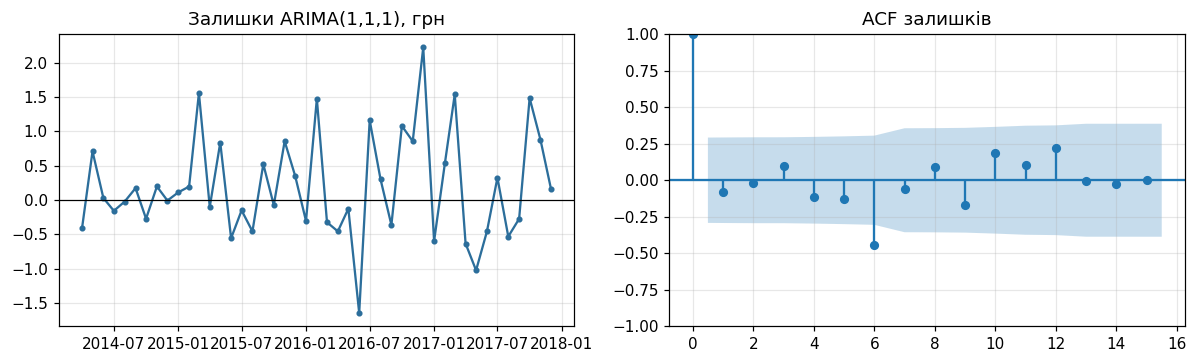

середнє залишків: 0.191 грн (модель без дрейфу)


,lb_stat,lb_pvalue
6,12.9825,0.0433
12,21.1792,0.0478


In [9]:
# Завдання 7. Модель ARIMA
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

warnings.filterwarnings('ignore')

def arima_cv(order, trend='n'):
    true, pred = [], []
    for _, tr, te in folds():
        fit = ARIMA(tr, order=order, trend=trend).fit()
        true.append(te)
        pred.append(fit.get_forecast(H).predicted_mean)
    return np.concatenate(true), np.concatenate(pred)


arima_true, arima_pred = arima_cv((1, 1, 1))
table = cv.copy()
table.loc['ARIMA(1,1,1)'] = scores(arima_true, arima_pred)
for order in [(1, 1, 0), (0, 1, 1)]:
    t, p = arima_cv(order, trend='t')
    table.loc['ARIMA%s + дрейф' % str(order).replace(' ', '')] = scores(t, p)
display(table.round(3))

best = cv['MAE'].idxmin()
print('найкращий базис: %s' % best)
print('ARIMA(1,1,1) гірша за нього: MAE у %.2f раза, RMSE у %.2f раза'
      % (table.loc['ARIMA(1,1,1)', 'MAE'] / cv.loc[best, 'MAE'], table.loc['ARIMA(1,1,1)', 'RMSE'] / cv.loc[best, 'RMSE']))

full = ARIMA(values, order=(1, 1, 1)).fit()
print()
print(full.summary().tables[1])
resid = pd.Series(full.resid[1:], index=y.index[1:])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(resid.index, resid.values, color='#2C6E9B', marker='o', ms=3)
axes[0].axhline(0, color='black', lw=0.8)
axes[0].set_title('Залишки ARIMA(1,1,1), грн')
plot_acf(resid, lags=15, ax=axes[1], title='ACF залишків')
plt.tight_layout()
plt.show()
print('середнє залишків: %.3f грн (модель без дрейфу)' % resid.mean())
display(acorr_ljungbox(resid, lags=[6, 12], return_df=True).round(4))

**Висновок до завдання 7:**

1. ARIMA(1,1,1) на тих самих 7 фолдах × 3 кроки: **MAE 1,710, RMSE 2,174, MAPE 4,40 %**.
2. Свій порядок я обрав би за ACF і PACF першої різниці (d = 1 за тестами із завдання 5). В обох функціях біля межі лише лаг 1 (0,30 при межі ±0,29), далі вони обриваються — це AR(1) або MA(1) для різниці. Середня різниця явно не нуль (дрейф 0,59 грн/міс), тому модель потрібна з константою: **ARIMA(0,1,1) + дрейф** (або ARIMA(1,1,0) + дрейф). Лаг 6 (−0,39) значущий, але сезонну ARIMA на 46 точках надійно не оцінити.
3. ARIMA(1,1,1) **програє найкращому базису**:
   * за MAE — у 1,46 раза (1,710 проти 1,171 у дрейфу);
   * за RMSE — у 1,33 раза (2,174 проти 1,631);
   * за MAE поступається навіть наївному (1,639).
   
   Причина: у statsmodels модель із d = 1 не має константи, тож не бачить дрейфу і після кожного стрибка прогнозує згасання. ARIMA(0,1,1) + дрейф дає MAE 1,187 і RMSE 1,618 — практично як дрейф. **Прямий висновок:** ARIMA(1,1,1) у такому вигляді права на існування для цього ряду не має. Складніша модель виправдана лише тоді, коли б'є простий базис, а тут найкраще, що вдається, — зрівнятися з ним.
4. Залишки ARIMA(1,1,1) зміщені вгору (середнє +0,19 грн — та сама відсутність дрейфу). Тест Льюнга–Бокса дає p = 0,043 на лагу 6 і p = 0,048 на лагу 12 (< 0,05), тобто **структура в залишках лишилась** — це пів­річна, сезонна автокореляція.

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

точка зміни: 03.2017, t = 16.07
середнє до: 27.85 грн, після: 44.85 грн
бутстреп приростів (2000 рядів без зламу): медіана max|t| = 13.5, 95-й процентиль = 16.1
p-значення зламу проти «просто тренду» = 0.054
скан приростів: швидкість зростання змінилась у 02.2015, t = 4.35, приріст до 0.05, після 0.74 грн/міс
перестановочний p для зміни темпу = 0.006 (95-й процентиль max|t| = 3.40)


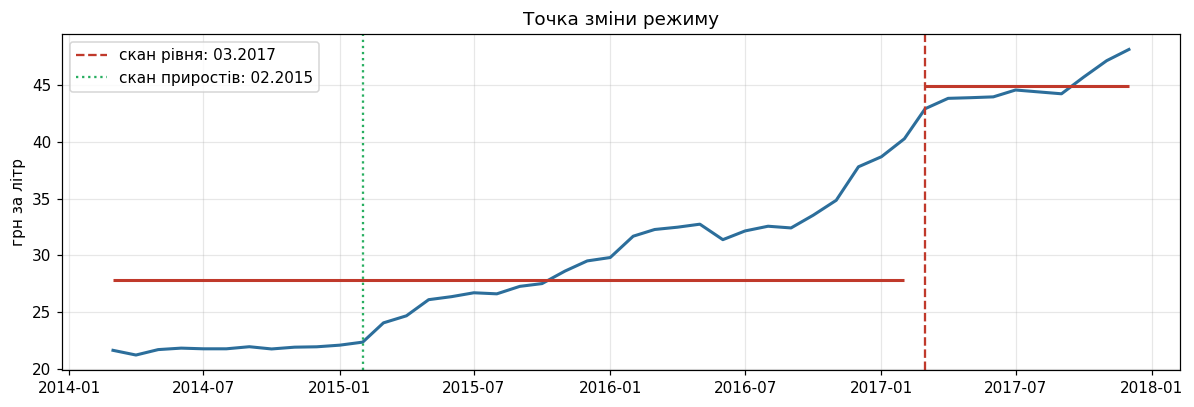

In [10]:
# Завдання 8. Точка зміни режиму
def scan(x, min_size=6):
    best_k, best_t = None, 0.0
    for k in range(min_size, len(x) - min_size + 1):
        a, b = x[:k], x[k:]
        t = (b.mean() - a.mean()) / np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
        if abs(t) > abs(best_t):
            best_k, best_t = k, t
    return best_k, best_t


k, t_stat = scan(values)
print('точка зміни: %s, t = %.2f' % (y.index[k].strftime('%m.%Y'), t_stat))
print('середнє до: %.2f грн, після: %.2f грн' % (values[:k].mean(), values[k:].mean()))

rng = np.random.default_rng(42)
steps = np.diff(values)
sim = []
for _ in range(2000):
    fake = values[0] + np.concatenate([[0], np.cumsum(rng.choice(steps, size=len(steps), replace=True))])
    sim.append(abs(scan(fake)[1]))
sim = np.array(sim)
p_boot = np.mean(sim >= abs(t_stat))
print('бутстреп приростів (2000 рядів без зламу): медіана max|t| = %.1f, 95-й процентиль = %.1f'
      % (np.median(sim), np.percentile(sim, 95)))
print('p-значення зламу проти «просто тренду» = %.3f' % p_boot)

kd, td = scan(steps)
print('скан приростів: швидкість зростання змінилась у %s, t = %.2f, приріст до %.2f, після %.2f грн/міс'
      % (y.index[kd + 1].strftime('%m.%Y'), td, steps[:kd].mean(), steps[kd:].mean()))
perm = np.array([abs(scan(rng.permutation(steps))[1]) for _ in range(2000)])
print('перестановочний p для зміни темпу = %.3f (95-й процентиль max|t| = %.2f)' % (np.mean(perm >= abs(td)), np.percentile(perm, 95)))

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(y.index, values, color='#2C6E9B', lw=2)
ax.axvline(y.index[k], color='#C0392B', ls='--', label='скан рівня: %s' % y.index[k].strftime('%m.%Y'))
ax.hlines([values[:k].mean(), values[k:].mean()], [y.index[0], y.index[k]], [y.index[k - 1], y.index[-1]],
          colors='#C0392B', lw=2)
ax.axvline(y.index[kd + 1], color='#27AE60', ls=':', label='скан приростів: %s' % y.index[kd + 1].strftime('%m.%Y'))
ax.set_title('Точка зміни режиму')
ax.set_ylabel('грн за літр')
ax.legend()
plt.tight_layout()
plt.show()

**Висновок до завдання 8:**

1. Графік із позначеною датою — вище.
2. Скан рівня: **03.2017, t = 16,07**; середнє до — **27,85** грн, після — **44,85** грн.
3. **Злам рівня незначущий.** Звичайна t-таблиця тут непридатна: перебрано 35 дат, і ряд має тренд, тож будь-яке ділення дає велике t. Бутстреп приростів (2000 рядів із тими самими місячними змінами, але без зламу) дає 95-й процентиль max|t| = 16,1 і **p = 0,054**: злам у 03.2017 не виділяється на тлі звичайного тренду.

   Зате скан приростів знаходить **зміну швидкості зростання в 02.2015**: до неї ціна майже стояла (+0,05 грн/міс), після — зростала на +0,74 грн/міс (t = 4,35, перестановочний **p = 0,006** — значущо). Для цієї дати є зовнішнє пояснення: у лютому 2015 НБУ перейшов до плаваючого курсу, гривня знецінилась, і почалась висока інфляція.
4. Сезонний сплеск повторюється щороку в ті самі місяці й не змінює подальшого рівня — такі в ряді зимові стрибки 2015, 2016 і 2017 років. Точка зміни режиму одноразова і стійка: після 02.2015 темп зростання змінився надовго, і повернення до попереднього рівня немає.

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

In [11]:
# Завдання 9. Рецензія на чужий аналіз
bad = pd.read_csv('ціни_україна_2014_2017.csv')
bad['date'] = pd.to_datetime(dict(year=bad['рік'], month=bad['місяць'], day=1))
pick = lambda market, good: bad[(bad['ринок'] == market) & (bad['товар'] == good)].set_index('date')['ціна'].sort_index()
vb = pick('Vinnytsia', 'Buckwheat grits - Retail')
beef = pick('Vinnytsia', 'Meat (beef) - Retail')
lv = pick('Lviv', 'Buckwheat grits - Retail')

print('клітинка 3: спостережень %d, а місяців у сітці %d; пропущено: %s'
      % (len(vb), len(grid), [d.strftime('%m.%Y') for d in grid.difference(vb.index)]))
for name, x in [('гречка', vb), ('яловичина', beef)]:
    mae = x.diff().abs().mean()
    print('клітинка 7: %-9s MAE наївного = %.2f грн, середня ціна = %.2f грн, MAE/ціна = %.1f %%'
          % (name, mae, x.mean(), 100 * mae / x.mean()))
print('клітинка 9: кореляція рівнів = %.3f, кореляція місячних змін = %.3f'
      % (vb.corr(lv), vb.diff().corr(lv.diff())))
p_adf = adfuller(vb, autolag='AIC')[1]
print('клітинка 13: ADF p = %.3f > 0.05 → H0 «нестаціонарний» НЕ відхиляється' % p_adf)
vbg = vb.reindex(grid).interpolate('linear')
st = STL(vbg, period=12, robust=True).fit()
print('клітинка 11: F_S гречки = %.3f' % max(0, 1 - st.resid.var() / (st.seasonal + st.resid).var()))
z = (vb - vb.mean()) / vb.std()
print('клітинка 15: поріг у коді 1.3σ (а в тексті 2σ); |z| > 2 мають %d місяців, |z| > 1.3 — %d'
      % (int((z.abs() > 2).sum()), int((z.abs() > 1.3).sum())))
print('клітинка 19: останнє значення %.2f грн, а прогноз на 12.2018 = 8.95 грн — це падіння, хоча висновок «зростання»'
      % vb.iloc[-1])

клітинка 3: спостережень 45, а місяців у сітці 46; пропущено: ['08.2017']
клітинка 7: гречка    MAE наївного = 1.38 грн, середня ціна = 21.32 грн, MAE/ціна = 6.5 %
клітинка 7: яловичина MAE наївного = 1.51 грн, середня ціна = 78.47 грн, MAE/ціна = 1.9 %
клітинка 9: кореляція рівнів = 0.996, кореляція місячних змін = 0.936
клітинка 13: ADF p = 0.233 > 0.05 → H0 «нестаціонарний» НЕ відхиляється
клітинка 11: F_S гречки = 0.262
клітинка 15: поріг у коді 1.3σ (а в тексті 2σ); |z| > 2 мають 0 місяців, |z| > 1.3 — 12
клітинка 19: останнє значення 17.67 грн, а прогноз на 12.2018 = 8.95 грн — це падіння, хоча висновок «зростання»


**Висновок до завдання 9:**

1. Знайдені методологічні помилки (номери клітинок — як у зошиті колеги):

| клітинка | суть помилки | чим небезпечна |
|---|---|---|
| 3 | «пропусків немає»: `isna()` перевірено на ряді без повної сітки, а точок 45 замість 46 (немає 08.2017) | усі лаги, `shift`, `period=12` після 07.2017 зсуваються на місяць; модель вважає 09.2017 наступним після 07.2017 |
| 5 | висновок про купівельну спроможність за номінальною ціною і лише двома крайніми точками | без доходів та інфляції такий висновок дані не підтримують; дві точки чутливі до випадкових коливань |
| 7 | MAE гречки й яловичини порівняно в гривнях | MAE залежить від масштабу: відносно ціни яловичина прогнозується **краще** (1,9 % проти 6,5 %) — висновок протилежний |
| 9 | кореляція рівнів двох трендових рядів (r = 0,996) подана як «Львів визначає Вінницю» | спільний тренд (інфляція) дає високу кореляцію будь-яких цін; кореляція не означає причинності |
| 11 | «STL виділив сезонну складову, отже ряд сезонний» | STL повертає сезонну складову завжди; F_S гречки = 0,26 < 0,3, тобто сезонності фактично немає, а сезонні моделі — без підстав |
| 13 | ADF прочитано навпаки: p = 0,233 > 0,05 означає, що H₀ «нестаціонарний» **не** відхиляється; далі подвійне диференціювання «для надійності», без KPSS | неправильний порядок d, надмірне диференціювання |
| 15 | «аномалії» шукано на рівні трендового ряду, ще й з порогом 1,3σ, хоча в тексті 2σ | «аномаліями» став увесь 2014 рік і літо 2016 — це наслідок тренду, а не події; з порогом 2σ аномалій 0 |
| 17 | випадковий `train_test_split` для часового ряду; прогноз уперед порівнюється з `np.sort(y_te)` — відсортованими значеннями з середини ряду; сезонний наївний рахується на інших точках | витік майбутнього і метрика без сенсу; «висока точність» 8,73 грн при ціні 7–18 грн — це похибка 50–100 % |
| 19 | фінальна модель ARIMA(2,2,1), а оцінювалась ARIMA(1,1,1); d = 2 без підстав; прогноз 8,95 грн на 12.2018 означає падіння вдвічі від 17,67, а висновок — «ціна зростатиме» | модель без перевірки, висновок суперечить власному числу, немає довірчих інтервалів |
| 21 | стовпчики з обрізаною віссю Y (від 0,995 · min) і лише 6 вибраних місяців | дрібна зміна виглядає «стрімким зростанням» — маніпулятивна візуалізація |
| 22 | загальні висновки повторюють хибні твердження (сезонний, стаціонарний, «Львів визначає», «висока точність») | хибні висновки потрапляють у підсумок звіту |

2. Як виправити три найсерйозніші:
   * **Клітинка 3.** Привести ряд до повної місячної сітки (`reindex(pd.date_range(..., freq='MS'))`), явно знайти 08.2017, заповнити його лінійною інтерполяцією і позначити як оцінку.
   * **Клітинка 17.** Замість випадкового поділу — ретроспективна перевірка з рухомим початком (7 фолдів × 3 кроки). На тих самих фолдах порівняти з наївним прогнозом і дрейфом; не сортувати тестові значення.
   * **Клітинки 13 і 19.** Читати ADF правильно (велике p — нестаціонарний) і перевіряти разом із KPSS, взяти d = 1. Для прогнозу брати ту саму модель, яку оцінювали, і звіряти текст висновку з надрукованим числом.

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [12]:
# Завдання 10. Експорт ряду для Orange
export = pd.DataFrame({'date': y.index.strftime('%Y-%m-%d'), 'price': y.values})
export.to_csv('ряд_для_orange.csv', index=False, encoding='utf-8')

check = pd.read_csv('ряд_для_orange.csv')
print('рядків даних:', len(check), '| порожніх значень:', int(check.isna().sum().sum()))
print('стовпці:', list(check.columns), '| перша дата:', check['date'].iloc[0], '| остання:', check['date'].iloc[-1])
print('дати у форматі РРРР-ММ-ДД:', bool(check['date'].str.fullmatch(r'\d{4}-\d{2}-01').all()))
print('збігається з рядом у Python:', bool(np.allclose(check['price'].values, y.values)))
print(check.iloc[40:43].to_string(index=False))

рядків даних: 46 | порожніх значень: 0
стовпці: ['date', 'price'] | перша дата: 2014-03-01 | остання: 2017-12-01
дати у форматі РРРР-ММ-ДД: True
збігається з рядом у Python: True
      date    price
2017-07-01 44.54000
2017-08-01 44.37335
2017-09-01 44.20670


**Висновок до завдання 10:**

Файл `ряд_для_orange.csv` має **46 рядків даних** плюс заголовок і **0 порожніх значень**. Стовпці: `date` у форматі РРРР-ММ-ДД (перше число місяця) та `price`; роздільник — кома, кодування UTF-8. Значення збігаються з рядом у Python, зокрема заповнений місяць 08.2017 = 44,37335 грн.

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

Потік у Orange (потік_orange.ows):


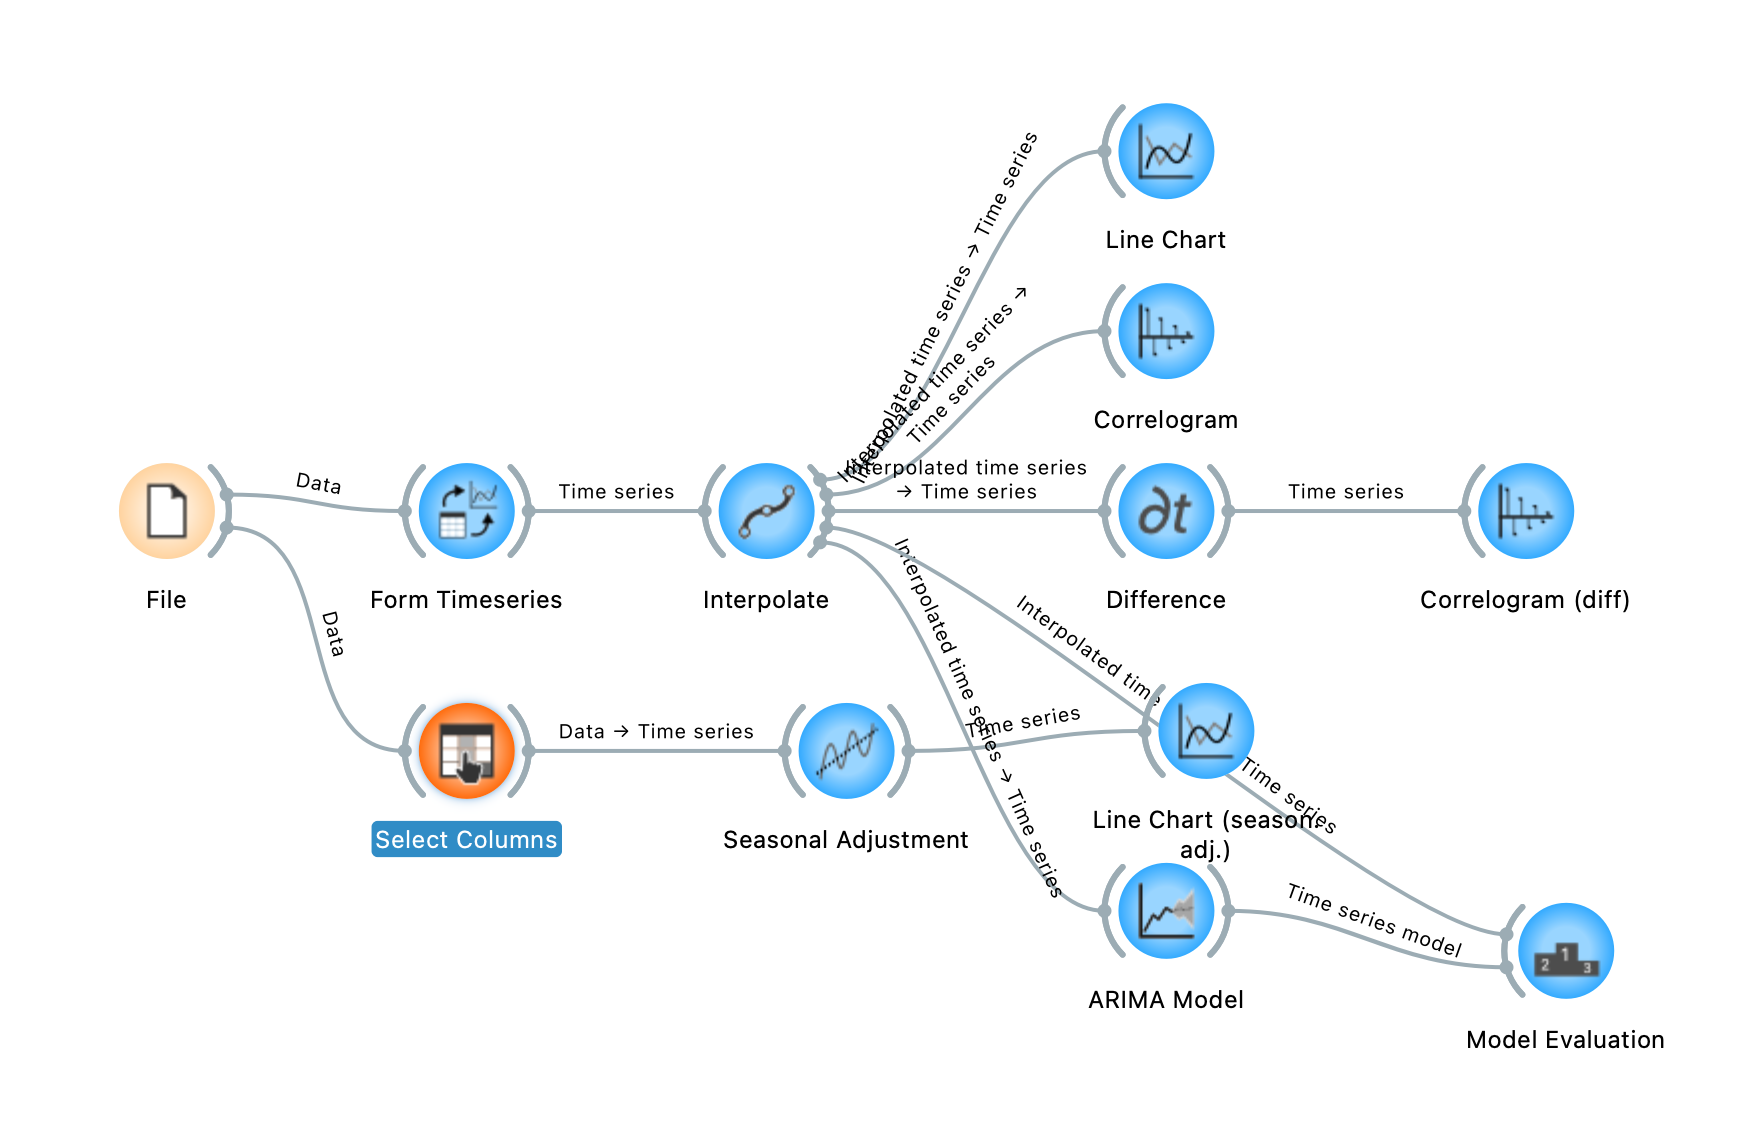

Віджет File: date — datetime, price — numeric, роль target


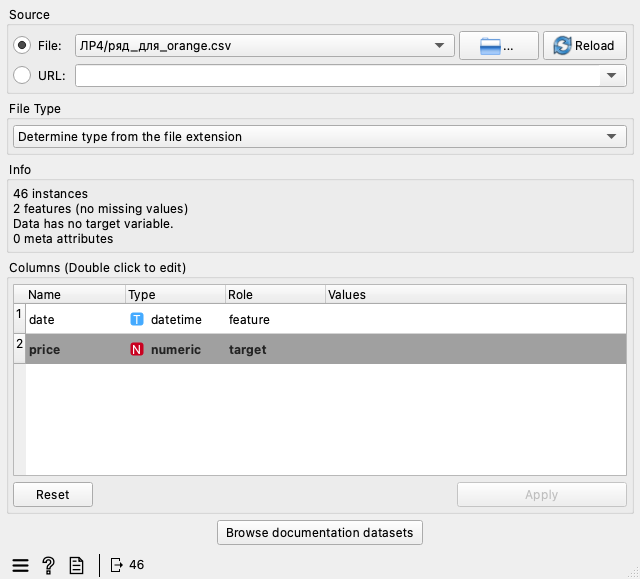

Віджет Form Timeseries (у старих версіях — As Timeseries): часова змінна date


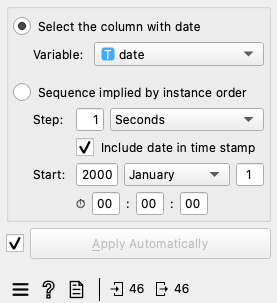

Line Chart у Orange:


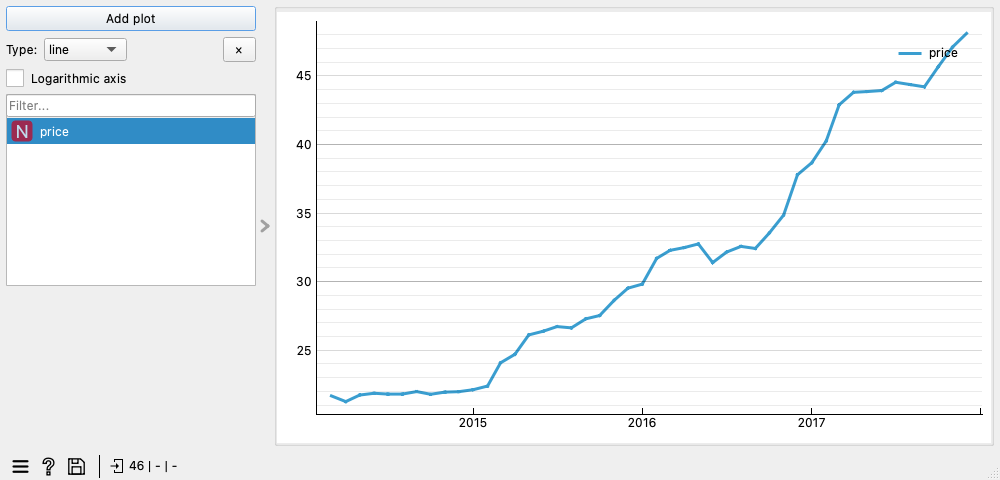

In [13]:
# Завдання 11. Потік опрацювання даних
SHOTS = 'orange_скріни/'
print('Потік у Orange (потік_orange.ows):')
display(Image(SHOTS + 'o11_workflow.png', width=900))
print('Віджет File: date — datetime, price — numeric, роль target')
display(Image(SHOTS + 'o11_file.png', width=520))
print('Віджет Form Timeseries (у старих версіях — As Timeseries): часова змінна date')
display(Image(SHOTS + 'o11_form_timeseries.png', width=360))
print('Line Chart у Orange:')
display(Image(SHOTS + 'o11_line_chart.png', width=900))

**Висновок до завдання 11:**

1. Потік — на першому знімку: **File → Form Timeseries → Interpolate → Line Chart**, плюс гілки для завдань 12–13. В Orange3-Timeseries 0.6.3 віджет **As Timeseries перейменовано на Form Timeseries**, суть та сама: обирається часова змінна `date`.
2. File розпізнав `date` як **datetime (time)**, а `price` — як **numeric**. Окремо довелося зробити `price` цільовою змінною (Role = target). Без цього ARIMA Model видає «Input time series doesn't contain a target variable», а Model Evaluation — «Data requires a target variable».
3. Line Chart в Orange **збігається з графіком 1 із завдання 3**: той самий рівень 21,7 → 48,1 грн, ті самі прискорення навесні 2015 і взимку 2016–2017, та сама гладка ділянка на місці 08.2017. Interpolate нічого не змінює, бо Orange отримав уже заповнений файл.

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

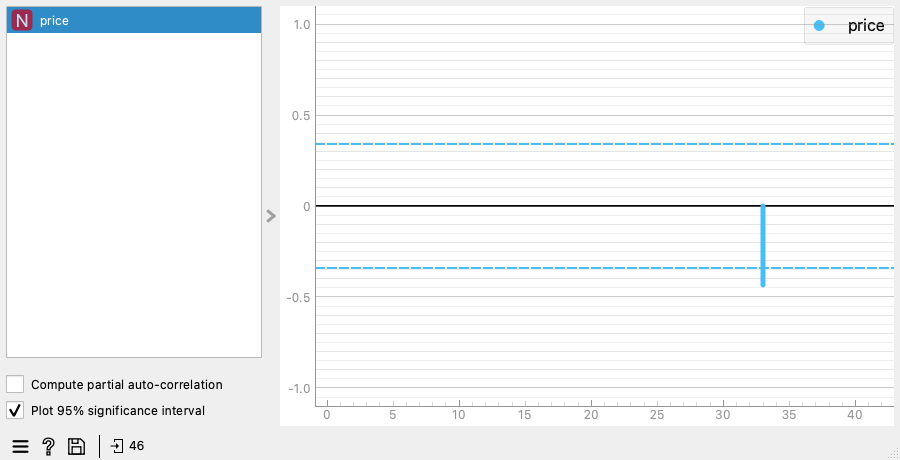

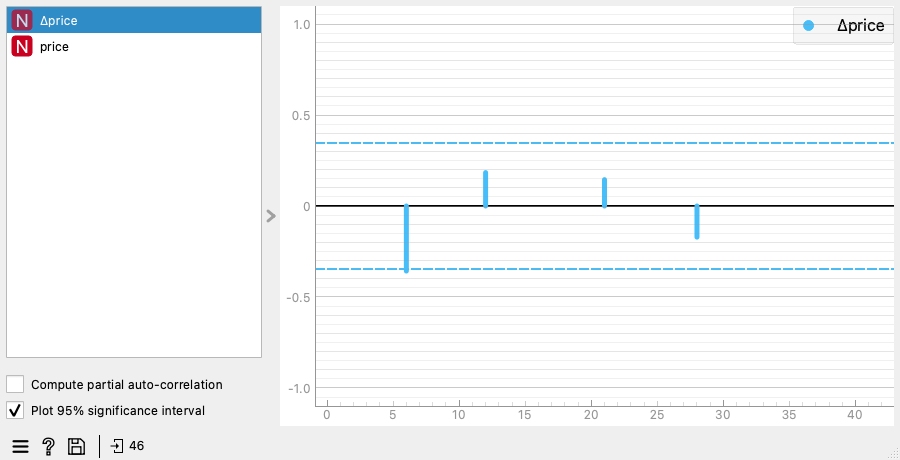

Orange показує лише локальні максимуми |ACF| (argrelextrema, order=3) до лагу 0.9·n:
  рівень   : {33: -0.434} | смуга ±0.339
  різниця  : {6: -0.357, 12: 0.184, 21: 0.145, 28: -0.171} | смуга ±0.345
statsmodels на тих самих лагах: рівень [-0.434] | різниця [-0.357  0.184  0.145 -0.171]

Seasonal Adjustment напряму з Interpolate — помилка Orange3-Timeseries 0.6.3 «variable date is not in domain»:


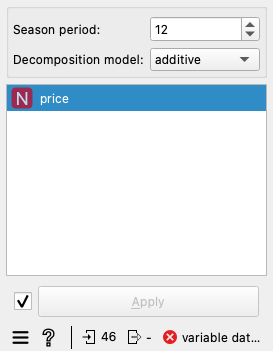

Обхід: File → Select Columns (date прибрано) → Seasonal Adjustment (additive, період 12) → Line Chart


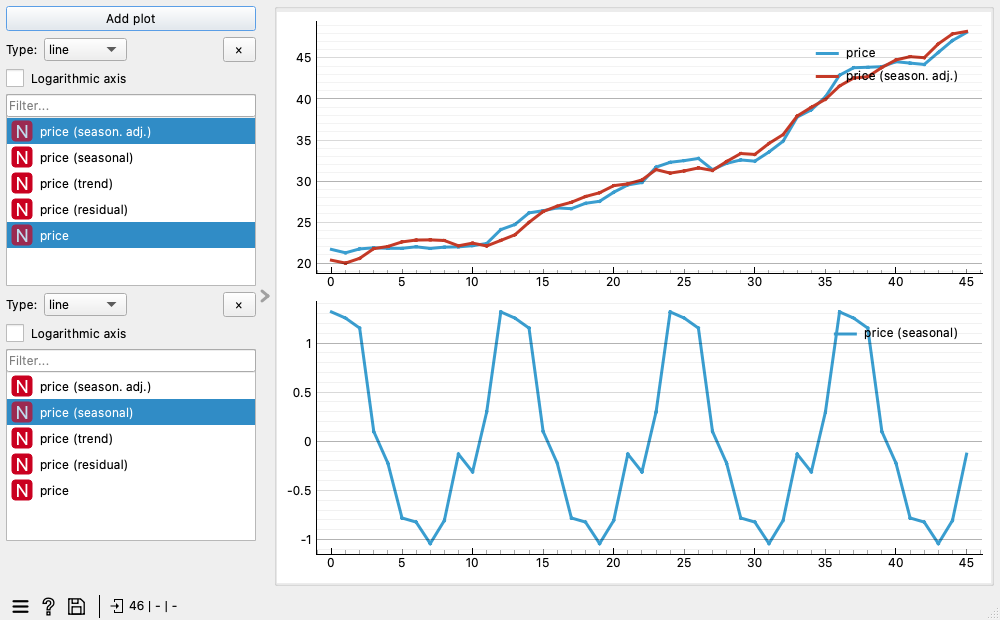

,03.2014,04.2014,05.2014,06.2014,07.2014,08.2014,09.2014,10.2014,11.2014,12.2014,01.2015,02.2015
"Orange (класична, additive)",1.32,1.25,1.15,0.10,-0.22,-0.78,-0.82,-1.04,-0.81,-0.13,-0.31,0.30
STL,0.93,0.43,0.97,0.88,0.54,0.17,0.22,-0.36,-0.37,-0.56,-1.05,-0.82


амплітуда сезонної складової: класична 2.36 грн, STL 4.92 грн
кореляція двох сезонних складових: 0.82


In [14]:
# Завдання 12. Автокореляція та диференціювання
display(Image(SHOTS + 'o12_correlogram.png', width=800))
display(Image(SHOTS + 'o12_correlogram_diff.png', width=800))

from scipy.signal import argrelextrema


def orange_like(x):
    r = acf(x, nlags=int(0.9 * len(x)), fft=True)
    lags = argrelextrema(np.abs(r), np.greater, order=3)[0]
    band = 1.96 * np.sqrt((1 + 2 * (r[lags] ** 2).sum()) / len(x))
    return pd.Series(r[lags], index=lags).round(3), round(band, 3)


lvl, band_lvl = orange_like(y.values)
dif, band_dif = orange_like(y.diff().interpolate(limit_direction='both').values)
print('Orange показує лише локальні максимуми |ACF| (argrelextrema, order=3) до лагу 0.9·n:')
print('  рівень   :', lvl.to_dict(), '| смуга ±%.3f' % band_lvl)
print('  різниця  :', dif.to_dict(), '| смуга ±%.3f' % band_dif)
print('statsmodels на тих самих лагах: рівень', np.round(acf(y, nlags=41)[lvl.index], 3),
      '| різниця', np.round(acf(y.diff().interpolate(limit_direction='both'), nlags=41)[dif.index], 3))

print()
print('Seasonal Adjustment напряму з Interpolate — помилка Orange3-Timeseries 0.6.3 «variable date is not in domain»:')
display(Image(SHOTS + 'o12_seasonal_adjustment_error.png', width=260))
print('Обхід: File → Select Columns (date прибрано) → Seasonal Adjustment (additive, період 12) → Line Chart')
display(Image(SHOTS + 'o12_season_adj_line_chart.png', width=900))

from statsmodels.tsa.seasonal import seasonal_decompose
classic = seasonal_decompose(y.values, model='additive', period=12)
compare_season = pd.DataFrame({'Orange (класична, additive)': classic.seasonal[:12], 'STL': stl.seasonal.values[:12]},
                              index=[d.strftime('%m.%Y') for d in y.index[:12]])
display(compare_season.round(2).T)
print('амплітуда сезонної складової: класична %.2f грн, STL %.2f грн'
      % (classic.seasonal.max() - classic.seasonal.min(), stl.seasonal.max() - stl.seasonal.min()))
print('кореляція двох сезонних складових: %.2f' % np.corrcoef(classic.seasonal, stl.seasonal)[0, 1])

**Висновок до завдання 12:**

1. Корелограми — вище (рівень і перша різниця).
2. **Висновки збігаються лише частково, хоча числа однакові.** Orange рахує ту саму `statsmodels.acf`, але:
   * показує лише лаги, де |ACF| має локальний максимум (`argrelextrema`, order = 3), до лагу 0,9 · n = 41;
   * для рівня це один стовпчик на лагу 33 (−0,434), а повільне згасання від 0,94 на корелограмі не видно взагалі;
   * для різниці показано лаги 6 (−0,357), 12 (0,184), 21 і 28 — на цих лагах значення збігаються з statsmodels до третього знака;
   * смуга значущості в Orange одна для всіх лагів: 1,96 · √((1 + 2Σρ²) / n) = ±0,34–0,35 проти ±0,29 у statsmodels для лагу 1.
   
   Головний висновок збігається: лаг 6 різниці значущий і в Orange (−0,357 при смузі ±0,345), і в Python (−0,39 при межі ±0,29). Але лаг 1 (0,30, у Python ледь значущий) Orange не показує, бо це не локальний максимум, а замість згасання ACF рівня видно лише лаг 33. Лаг 6 трохи відрізняється (−0,357 проти −0,39), бо Orange рахує по 46 точках: перший рядок після Difference порожній, і Orange його інтерполює.
3. **Seasonal Adjustment напряму після Interpolate в Orange3-Timeseries 0.6.3 падає** з помилкою «variable date is not in domain». Це вада віджета: він відкидає часову змінну, але лишає посилання на неї. Обхід: File → Select Columns (прибрати `date`) → Seasonal Adjustment → Line Chart.

   Orange використовує класичне розкладання (ковзні середні, additive, період 12). Його сезонна складова має амплітуду **2,36 грн** проти **4,92 грн** у STL, але той самий рисунок (кореляція 0,82): максимум у березні–травні, мінімум у вересні–жовтні. Сезонно скоригований ряд в Orange майже збігається з вихідним, бо сезонність мала порівняно з трендом.

## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

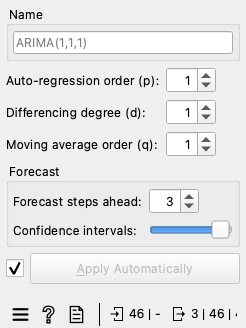

Model Evaluation, 7 фолдів × 3 кроки:


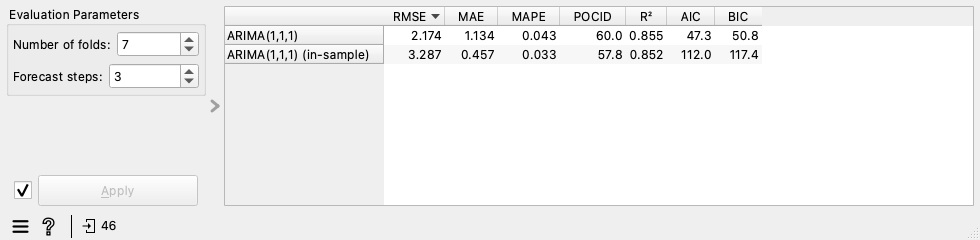

Model Evaluation з типовими налаштуваннями (20 фолдів × 3 кроки):


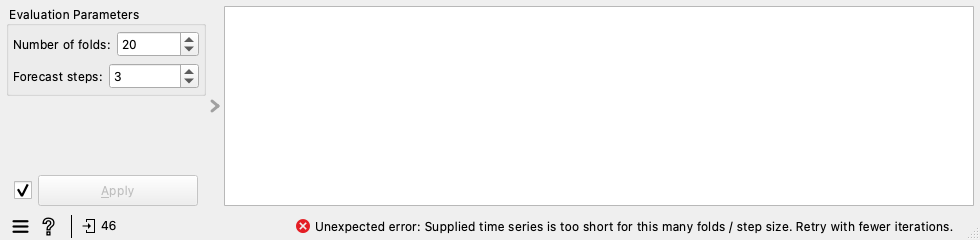

20 фолдів: потрібно 20 × 3 + 1 = 61 спостережень, є 46 → відмова
 7 фолдів: потрібно 7 × 3 + 1 = 22 спостережень, є 46 → рахує
найбільше фолдів при 3 кроках: 15

фолди Orange (train_end = −fold·steps):
  фолд 1: навчання на 03.2014–09.2017, прогноз 10.2017–12.2017
  фолд 2: навчання на 03.2014–06.2017, прогноз 07.2017–09.2017
  фолд 3: навчання на 03.2014–03.2017, прогноз 04.2017–06.2017
  фолд 4: навчання на 03.2014–12.2016, прогноз 01.2017–03.2017
  фолд 5: навчання на 03.2014–09.2016, прогноз 10.2016–12.2016
  фолд 6: навчання на 03.2014–06.2016, прогноз 07.2016–09.2016
  фолд 7: навчання на 03.2014–03.2016, прогноз 04.2016–06.2016


In [15]:
# Завдання 13. Модель і оцінювання
display(Image(SHOTS + 'o13_arima.png', width=360))
print('Model Evaluation, 7 фолдів × 3 кроки:')
display(Image(SHOTS + 'o13_model_evaluation_7x3.png', width=900))
print('Model Evaluation з типовими налаштуваннями (20 фолдів × 3 кроки):')
display(Image(SHOTS + 'o13_model_evaluation_20x3_error.png', width=900))

max_lag = max((1, 1, 1))
for n_folds in (20, 7):
    need = n_folds * H + max_lag
    print('%2d фолдів: потрібно %d × %d + %d = %d спостережень, є %d → %s'
          % (n_folds, n_folds, H, max_lag, need, n, 'відмова' if need > n else 'рахує'))
print('найбільше фолдів при 3 кроках: %d' % ((n - max_lag) // H))
print()
print('фолди Orange (train_end = −fold·steps):')
for f in range(1, 8):
    end = n - 3 * f
    print('  фолд %d: навчання на 03.2014–%s, прогноз %s–%s'
          % (f, y.index[end - 1].strftime('%m.%Y'), y.index[end].strftime('%m.%Y'), y.index[end + 2].strftime('%m.%Y')))

**Висновок до завдання 13:**

1. Таблиця Model Evaluation (7 фолдів × 3 кроки) для ARIMA(1,1,1): **RMSE 2,174, MAE 1,134, MAPE 0,043, POCID 60,0**, R² 0,855, AIC 47,3, BIC 50,8. Рядок «in-sample» — це оцінка підгонки на всьому ряді, а не прогноз.
2. З типовими 20 фолдами Orange видає **«Unexpected error: Supplied time series is too short for this many folds / step size. Retry with fewer iterations.»** Це не збій, а перевірка у `functions.py`: n_folds × forecast_steps + max_lag ≤ довжина ряду. Тут max_lag — найбільший порядок моделі (1), тож 20 · 3 + 1 = **61 > 46**. Найбільше можна 15 фолдів.
3. Orange навчає модель на спостереженнях до позиції −fold · steps. Фолд 1 — на 03.2014–09.2017 з прогнозом на 10–12.2017, …, фолд 7 — на 03.2014–03.2016 з прогнозом на 04–06.2016. Перевіряються ті самі 21 останні місяці (04.2016–12.2017), що й у Python, лише в зворотному порядку.

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [16]:
# Завдання 14. Чому числа не збігаються
orange = {'RMSE': 2.174, 'MAE': 1.134, 'MAPE': 0.043, 'POCID': 60.0}

e = arima_true - arima_pred
mine = {
    'RMSE': np.sqrt(np.sum(e ** 2) / len(e)),
    'MAE': np.median(np.abs(e)),
    'MAPE': np.mean(np.abs(e)) / np.mean(np.abs(arima_true)),
    'POCID': 100 * np.mean(np.diff(arima_true) * np.diff(arima_pred) > 0),
}
formulas = {
    'RMSE': 'sqrt(Σe² / n)',
    'MAE': 'median |e|',
    'MAPE': 'mean|e| / mean|y|  (частка)',
    'POCID': '100 · mean[Δy · Δŷ > 0] по склеєних фолдах',
}
usual = {
    'RMSE': np.sqrt(np.mean(e ** 2)),
    'MAE': np.mean(np.abs(e)),
    'MAPE': np.mean(np.abs(e / arima_true)) * 100,
    'POCID': np.nan,
}
rep = pd.DataFrame({'Orange': orange, 'відтворення в Python': mine, 'формула Orange': formulas,
                    'звична формула (Частина 1)': usual})
rep['збіг до 3-го знака'] = [round(mine[k], 3) == orange[k] for k in rep.index]
display(rep.round(4))
print('прогнози ARIMA(1,1,1) по 7 фолдах (порядок Orange: фолд 1 — останні 3 місяці):')
print(np.round(arima_pred, 3))

,Orange,відтворення в Python,формула Orange,звична формула (Частина 1),збіг до 3-го знака
RMSE,2.174,2.1736,sqrt(Σe² / n),2.1736,True
MAE,1.134,1.1342,median |e|,1.7099,True
MAPE,0.043,0.0434,mean|e| / mean|y| (частка),4.4020,True
POCID,60.000,60.0000,100 · mean[Δy · Δŷ > 0] по склеєних фолдах,NaN,True


прогнози ARIMA(1,1,1) по 7 фолдах (порядок Orange: фолд 1 — останні 3 місяці):
[44.189 44.175 44.162 44.199 44.42  44.607 44.615 46.241 47.78  39.381
 40.779 42.01  32.531 32.633 32.726 31.023 30.735 30.509 33.003 33.695
 34.361]


**Висновок до завдання 14:**

1. Таблиця на чотири рядки — вище: RMSE 2,174 = 2,1736; MAE 1,134 = 1,1342 (медіана |e|); MAPE 0,043 = 0,0434 (частка mean|e| / mean|y|); POCID 60,0 = 60,0. **Усі чотири відтворено до третього знака.** Прогнози Orange і Python ідентичні: той самий `statsmodels` ARIMA(1,1,1) без константи на тих самих 7 фолдах.
2. Назві не відповідають **MAE і MAPE**:
   * «MAE» в Orange — це **медіанна** абсолютна похибка (median |e| = 1,134), а не середня (mean |e| = 1,710 у Частині 1). На несиметричних похибках різниця в 1,5 раза.
   * «MAPE» — це **mean|e| / mean|y|** (зважена похибка, WAPE), до того ж **частка, а не відсоток**: 0,043 означає 4,3 %, тоді як звичайний MAPE = mean|e / y| · 100 = 4,40 %.
3. Одразу збігся **RMSE (2,174)**: формула однакова — корінь із середнього квадрата похибок по всіх 21 прогнозі.
4. Перш ніж порівнювати числа двох інструментів, треба перевірити:
   * ті самі дані (файл, заповнений пропуск);
   * ту саму модель (порядок, константа);
   * ту саму схему перевірки: фолди, горизонт, агрегування (Orange рахує по склеєних фолдах);
   * і насамперед **формули метрик та їхні одиниці**: медіана чи середнє, частка чи відсоток.

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [17]:
# Завдання 15. Матриця напрямку зміни
dt, dp = np.diff(arima_true), np.diff(arima_pred)
actual = np.where(dt > 0, 'зросла', 'впала')
predicted = np.where(dp > 0, 'зросла', 'впала')
matrix = pd.crosstab(pd.Series(actual, name='насправді'), pd.Series(predicted, name='модель'))
display(matrix)
hit = np.mean(actual == predicted) * 100
print('частка правильних напрямків: %.1f %% (POCID Orange = %.1f %%)' % (hit, orange['POCID']))
boundary = np.arange(1, len(dt) + 1) % H == 0
print('пар усього: %d, із них на стику фолдів: %d' % (len(dt), int(boundary.sum())))
print('правильних напрямків усередині фолдів: %.1f %%' % (np.mean((actual == predicted)[~boundary]) * 100))
always_up = np.mean(actual == 'зросла') * 100
print('тривіальне правило «завжди зростає»: %.1f %%' % always_up)

модель,впала,зросла
насправді,,
впала,4,5
зросла,3,8


частка правильних напрямків: 60.0 % (POCID Orange = 60.0 %)
пар усього: 20, із них на стику фолдів: 6
правильних напрямків усередині фолдів: 57.1 %
тривіальне правило «завжди зростає»: 55.0 %


**Висновок до завдання 15:**

1. Матриця напрямку зміни (20 пар сусідніх прогнозів, як рахує Orange):

| насправді \ модель | впала | зросла |
|---|---|---|
| впала | 4 | 5 |
| зросла | 3 | 8 |

2. Правильних напрямків 4 + 8 = **12 з 20 = 60,0 %** — збігається з POCID Orange (60,0). Увага: 6 із 20 пар припадають на стик фолдів, бо Orange склеює фолди й порівнює, наприклад, останній місяць фолду 2 з першим місяцем фолду 1. Усередині фолдів правильних лише 57,1 %.
3. Для рішення «купувати зараз чи чекати» модель **майже марна**. Тривіальне правило «ціна завжди зростає» вгадує напрямок у 55 % пар, модель — у 60 %, тобто додає один правильний випадок із 20. Це **інше питання**, ніж MAE і RMSE: вони міряють, наскільки далеко прогноз від ціни, а POCID — чи вгадано знак зміни. Модель може мати малу похибку й вгадувати напрямок навмання (як тут, коли за місяць ціна змінюється на копійки), і навпаки.

---
# Загальний висновок

Напишіть 8–12 речень, які відповідають на такі питання:

1. Чи є у вашому ряді сезонність і чим ви це довели?
2. Який метод прогнозування виявився найкращим і чи перевершив він найпростіший базис?
3. Чи знайшли ви точку зміни режиму; якщо так — чи є для неї зовнішнє пояснення?
4. Чому однаково названі метрики у двох середовищах дали різні числа?
5. Чого ви не змогли встановити через те, що ряд має лише 46 спостережень?

У ряді цін на сметану в Херсоні є сезонність: F_S = 0,82 > 0,3 (робастний STL — 0,53), і рисунок повторюється щороку — ціна росте взимку–навесні й стоїть влітку–восени. Проте тренд значно сильніший (F_T = 0,997), і на 46 точках сезонність майже не допомагає прогнозу: сезонний наївний — один із найгірших базисів. Найкращим методом виявився найпростіший дрейф (MAE 1,17, RMSE 1,63). Обов'язкова ARIMA(1,1,1) без константи йому програла (1,71 і 2,17), а ARIMA(0,1,1) з дрейфом лише зрівнялась — складна модель найпростіший базис не перевершила. Злам рівня в 03.2017 незначущий порівняно зі звичайним трендом (бутстреп p = 0,054). Натомість зміна темпу зростання в 02.2015 значуща (p = 0,006) і має зовнішнє пояснення — перехід до плаваючого курсу гривні та інфляцію 2015 року. В Orange та сама модель на тих самих 7 фолдах дала ті самі прогнози, а метрики відрізнились лише через означення: «MAE» там — медіана |e|, «MAPE» — частка mean|e| / mean|y|, а RMSE збігся точно. Усі чотири числа Orange я відтворив у Python до третього знака. Окремо з'ясувалось, що в Orange3-Timeseries 0.6.3 Seasonal Adjustment не працює з часовою змінною, а для ARIMA і Model Evaluation ціну треба явно зробити target. Через те що ряд має лише 46 спостережень, не вдалося надійно оцінити сезонну модель (менше чотирьох повних циклів), використати більше 15 фолдів чи горизонт понад кілька місяців, а POCID 60 % проти 55 % для правила «завжди зростає» на 20 парах статистично не відрізняється.

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | Claude|
| Для яких саме завдань | 1–15 і загальний висновок: код аналізу, чернетки висновків; потік Orange зібрано скриптом у справжньому Orange 3.40, знімки екрана зроблено ним же |
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | код завдань, деякі пояснення, файл потоку `потік_orange.ows`|
| Що ви змінили у згенерованому результаті й чому | *скріни Orange, вибір в завданнях і зроблено вручну помилковий аналіз* |
| Що з отриманого ви **перевірили самостійно** і яким способом | *перевірено результати скрипта для Orange та зроблено вручну* |
| Чи траплялися у відповідях ШІ помилки; якщо так — які | *траплялися помилки в будуванні графіків та користуванні Orange, також не логічно вибирає завдання* |

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: ______________________  Дата: ______________